# 01 — Datasheet Curves Extraction (config-driven)

All simulation conditions are read from **`config/inputs/<vendor>.yaml`** — the single
source of truth shared with the output-generation pipeline (`yaml_io`). Switch devices
by changing `VENDOR` below to any stem present in `config/inputs/`.
No conditions are hardcoded in this notebook.

Pin order is also config-driven: `pins.pin_order_semantic` maps logical roles
(drain/gate/source) to the subckt's actual header tokens, validated against the
model file by `parser.netlist.resolve_pin_connections` (IR/TI: D,G,S; EPC: G,D,S).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from common.plotting import setup_style, plot_curves
from config.yaml_io import load_input
from parser.netlist import resolve_pin_connections
from simulation.testbenches.static_sweep import StaticSweepTestbench
from simulation.testbenches.capacitance import CapacitanceTestbench
from simulation.testbenches.gate_charge import reconstruct_gate_charge, plot_gate_charge

# ── Device under test: pick any input config in config/inputs/ ────────────
# irfs7730pbf   - Infineon (MODPEX SPICE3 LEVEL=1)
# csd16412q5a   - TI NexFET (PSpice BSIM3v3 LEVEL=7)
# epc2216       - EPC eGaN FET (behavioral PSpice model, gate-first pins)
VENDOR = "cpm2-1200"

cfg = load_input(VENDOR)
cond = cfg["conditions"]
_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LIB = (_ROOT / cfg["library"]).resolve()
SUBCKT = cfg["subcircuit"]
TITLE = VENDOR.upper()

# Resolve X-instance connection order from the model header + config pin map
PIN_ROLES = resolve_pin_connections(
    LIB, SUBCKT, pin_order_semantic=cfg["pins"].get("pin_order_semantic"),
)
print(f"Device {VENDOR}: pin roles = {PIN_ROLES}")

setup_style()
static = StaticSweepTestbench()

Device cpm2-1200: pin roles = ['drain', 'gate', 'source', 'tj']


## Study 1 - Output Characteristics (Id vs Vds family)
Gate family from the input config.

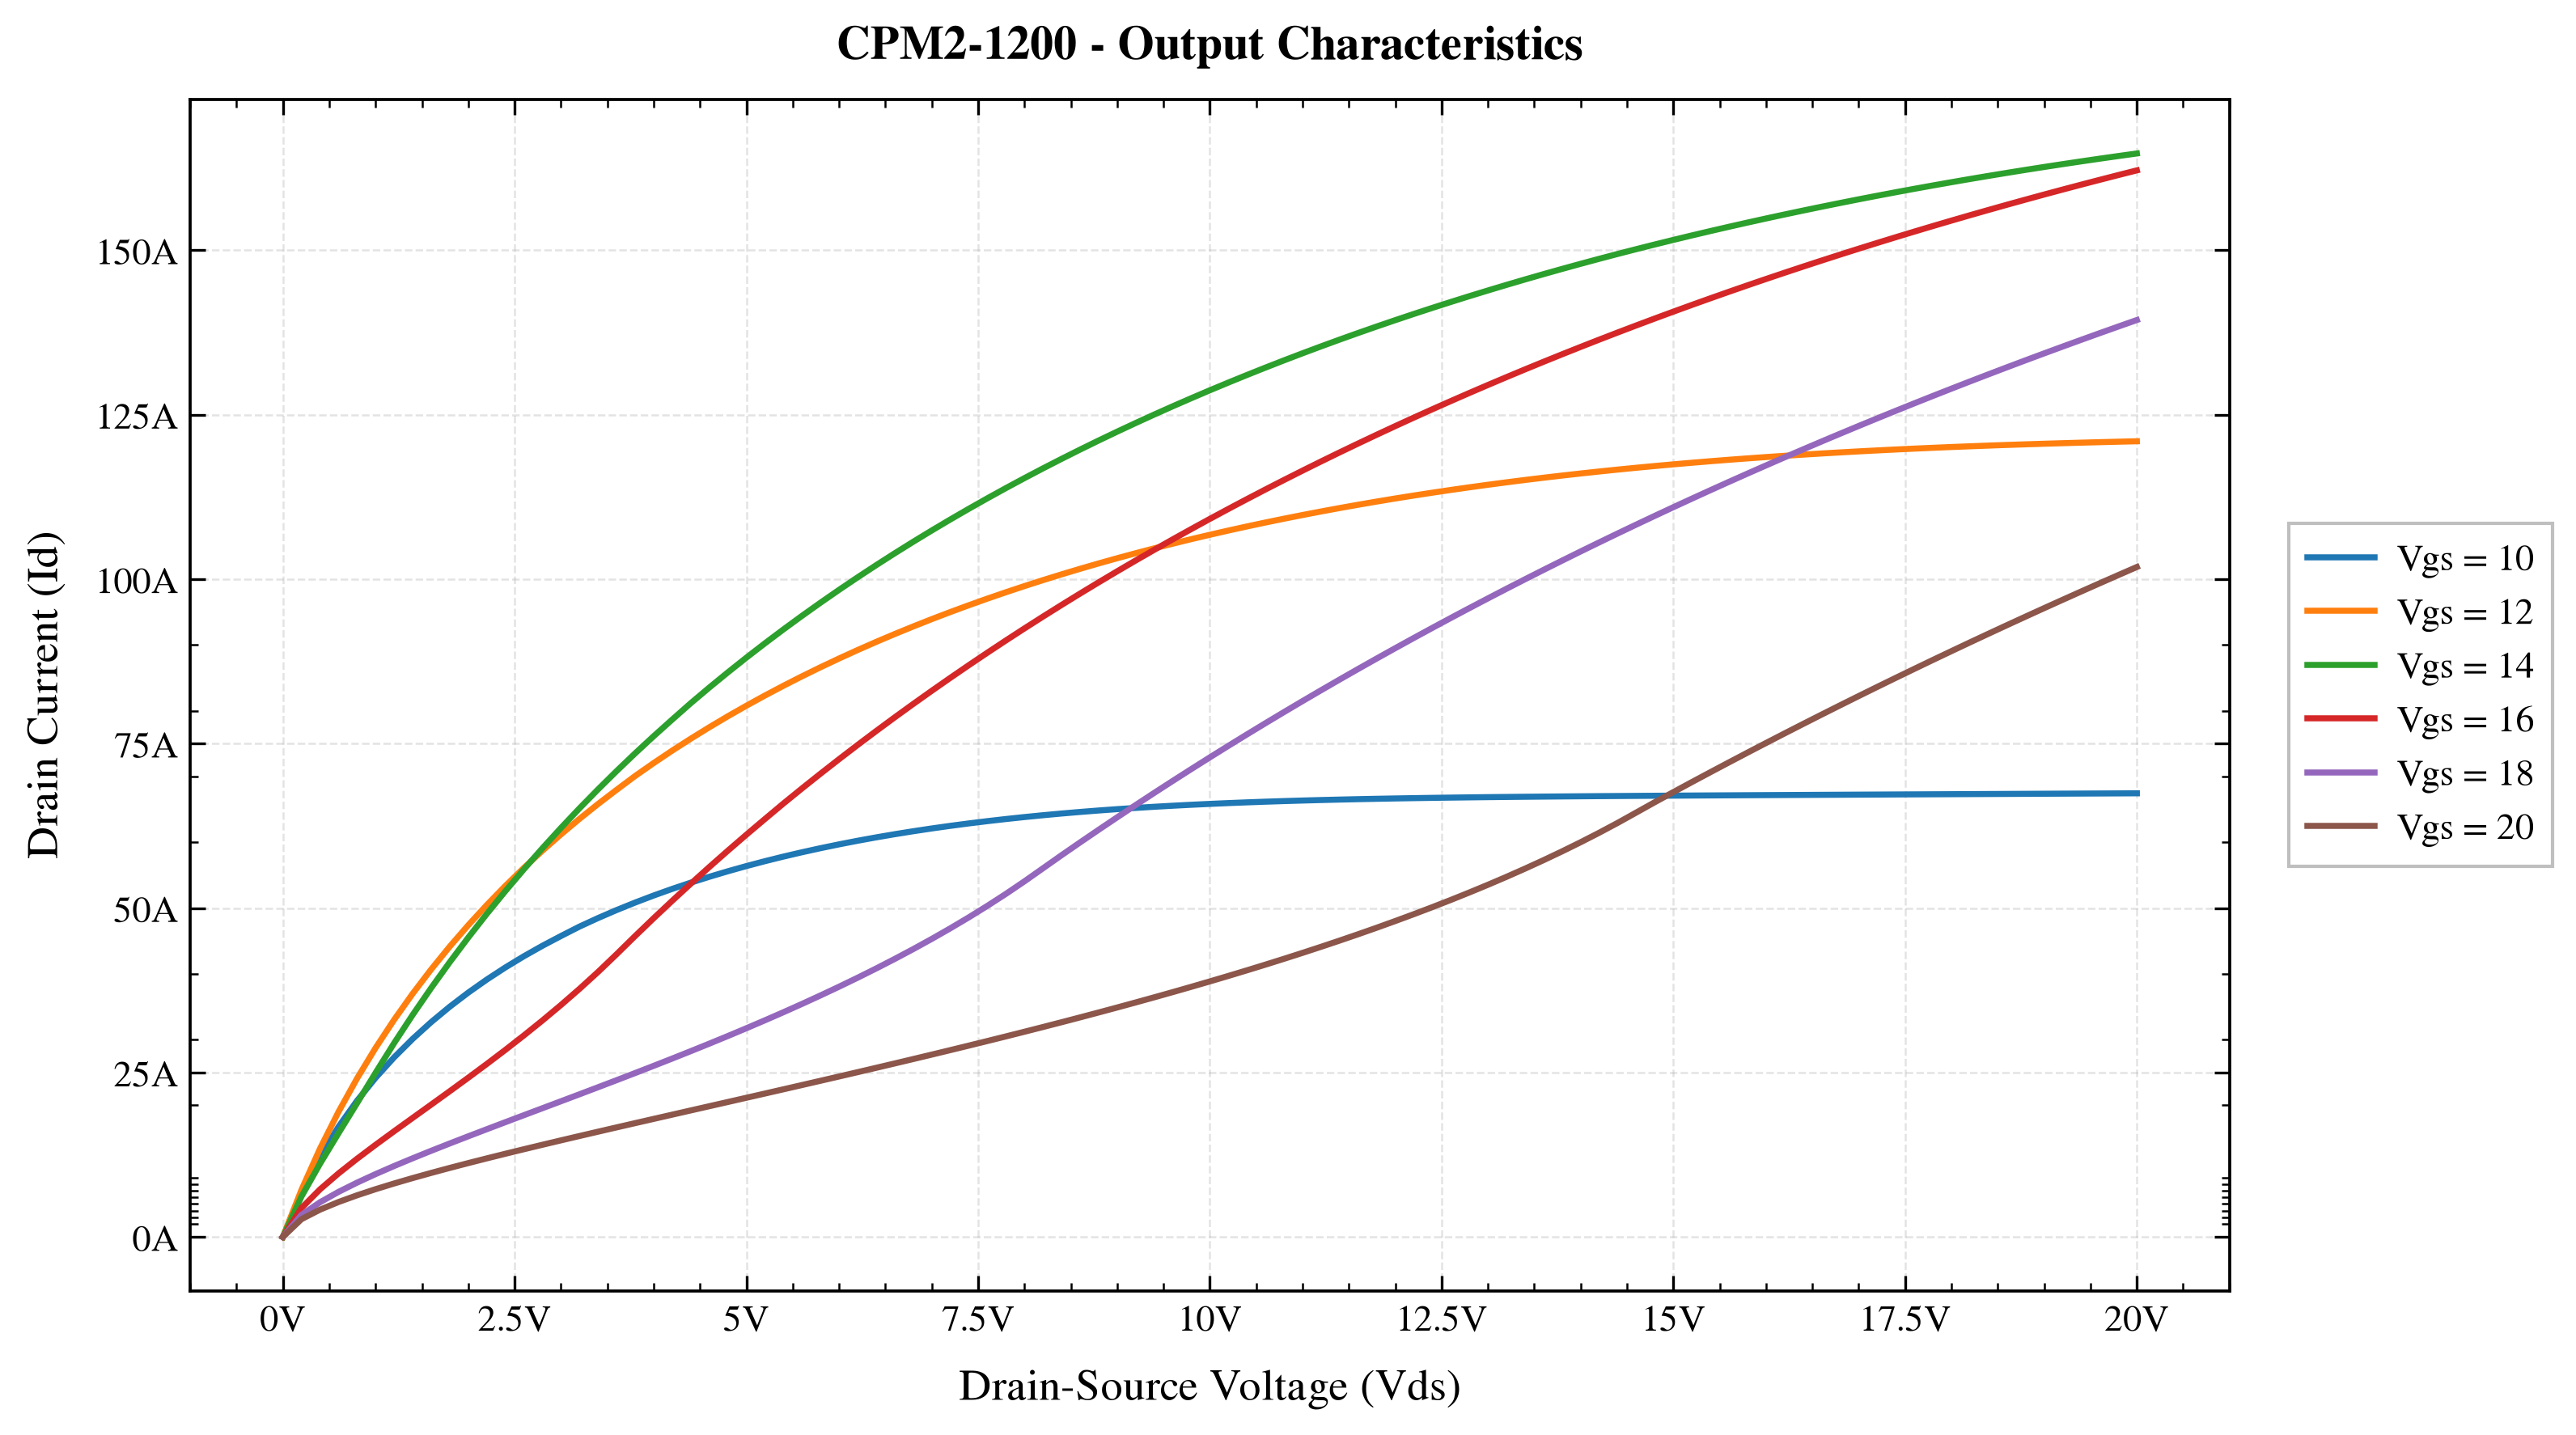

In [2]:
output_curves = static.run_output_characteristics(
    LIB, SUBCKT,
    vgs_list=cond["Vgs_sweep"],
    vds_max=cond["Vds_sweep_max"], vds_points=cond["Vds_points"],
    pin_roles=PIN_ROLES,
)
fig1, ax1 = plot_curves(output_curves, f"{TITLE} - Output Characteristics")
plt.show()

## Study 2 - Transfer Characteristic (Id vs Vgs at fixed Vds)
Swept at the config's transfer reference drain voltage.

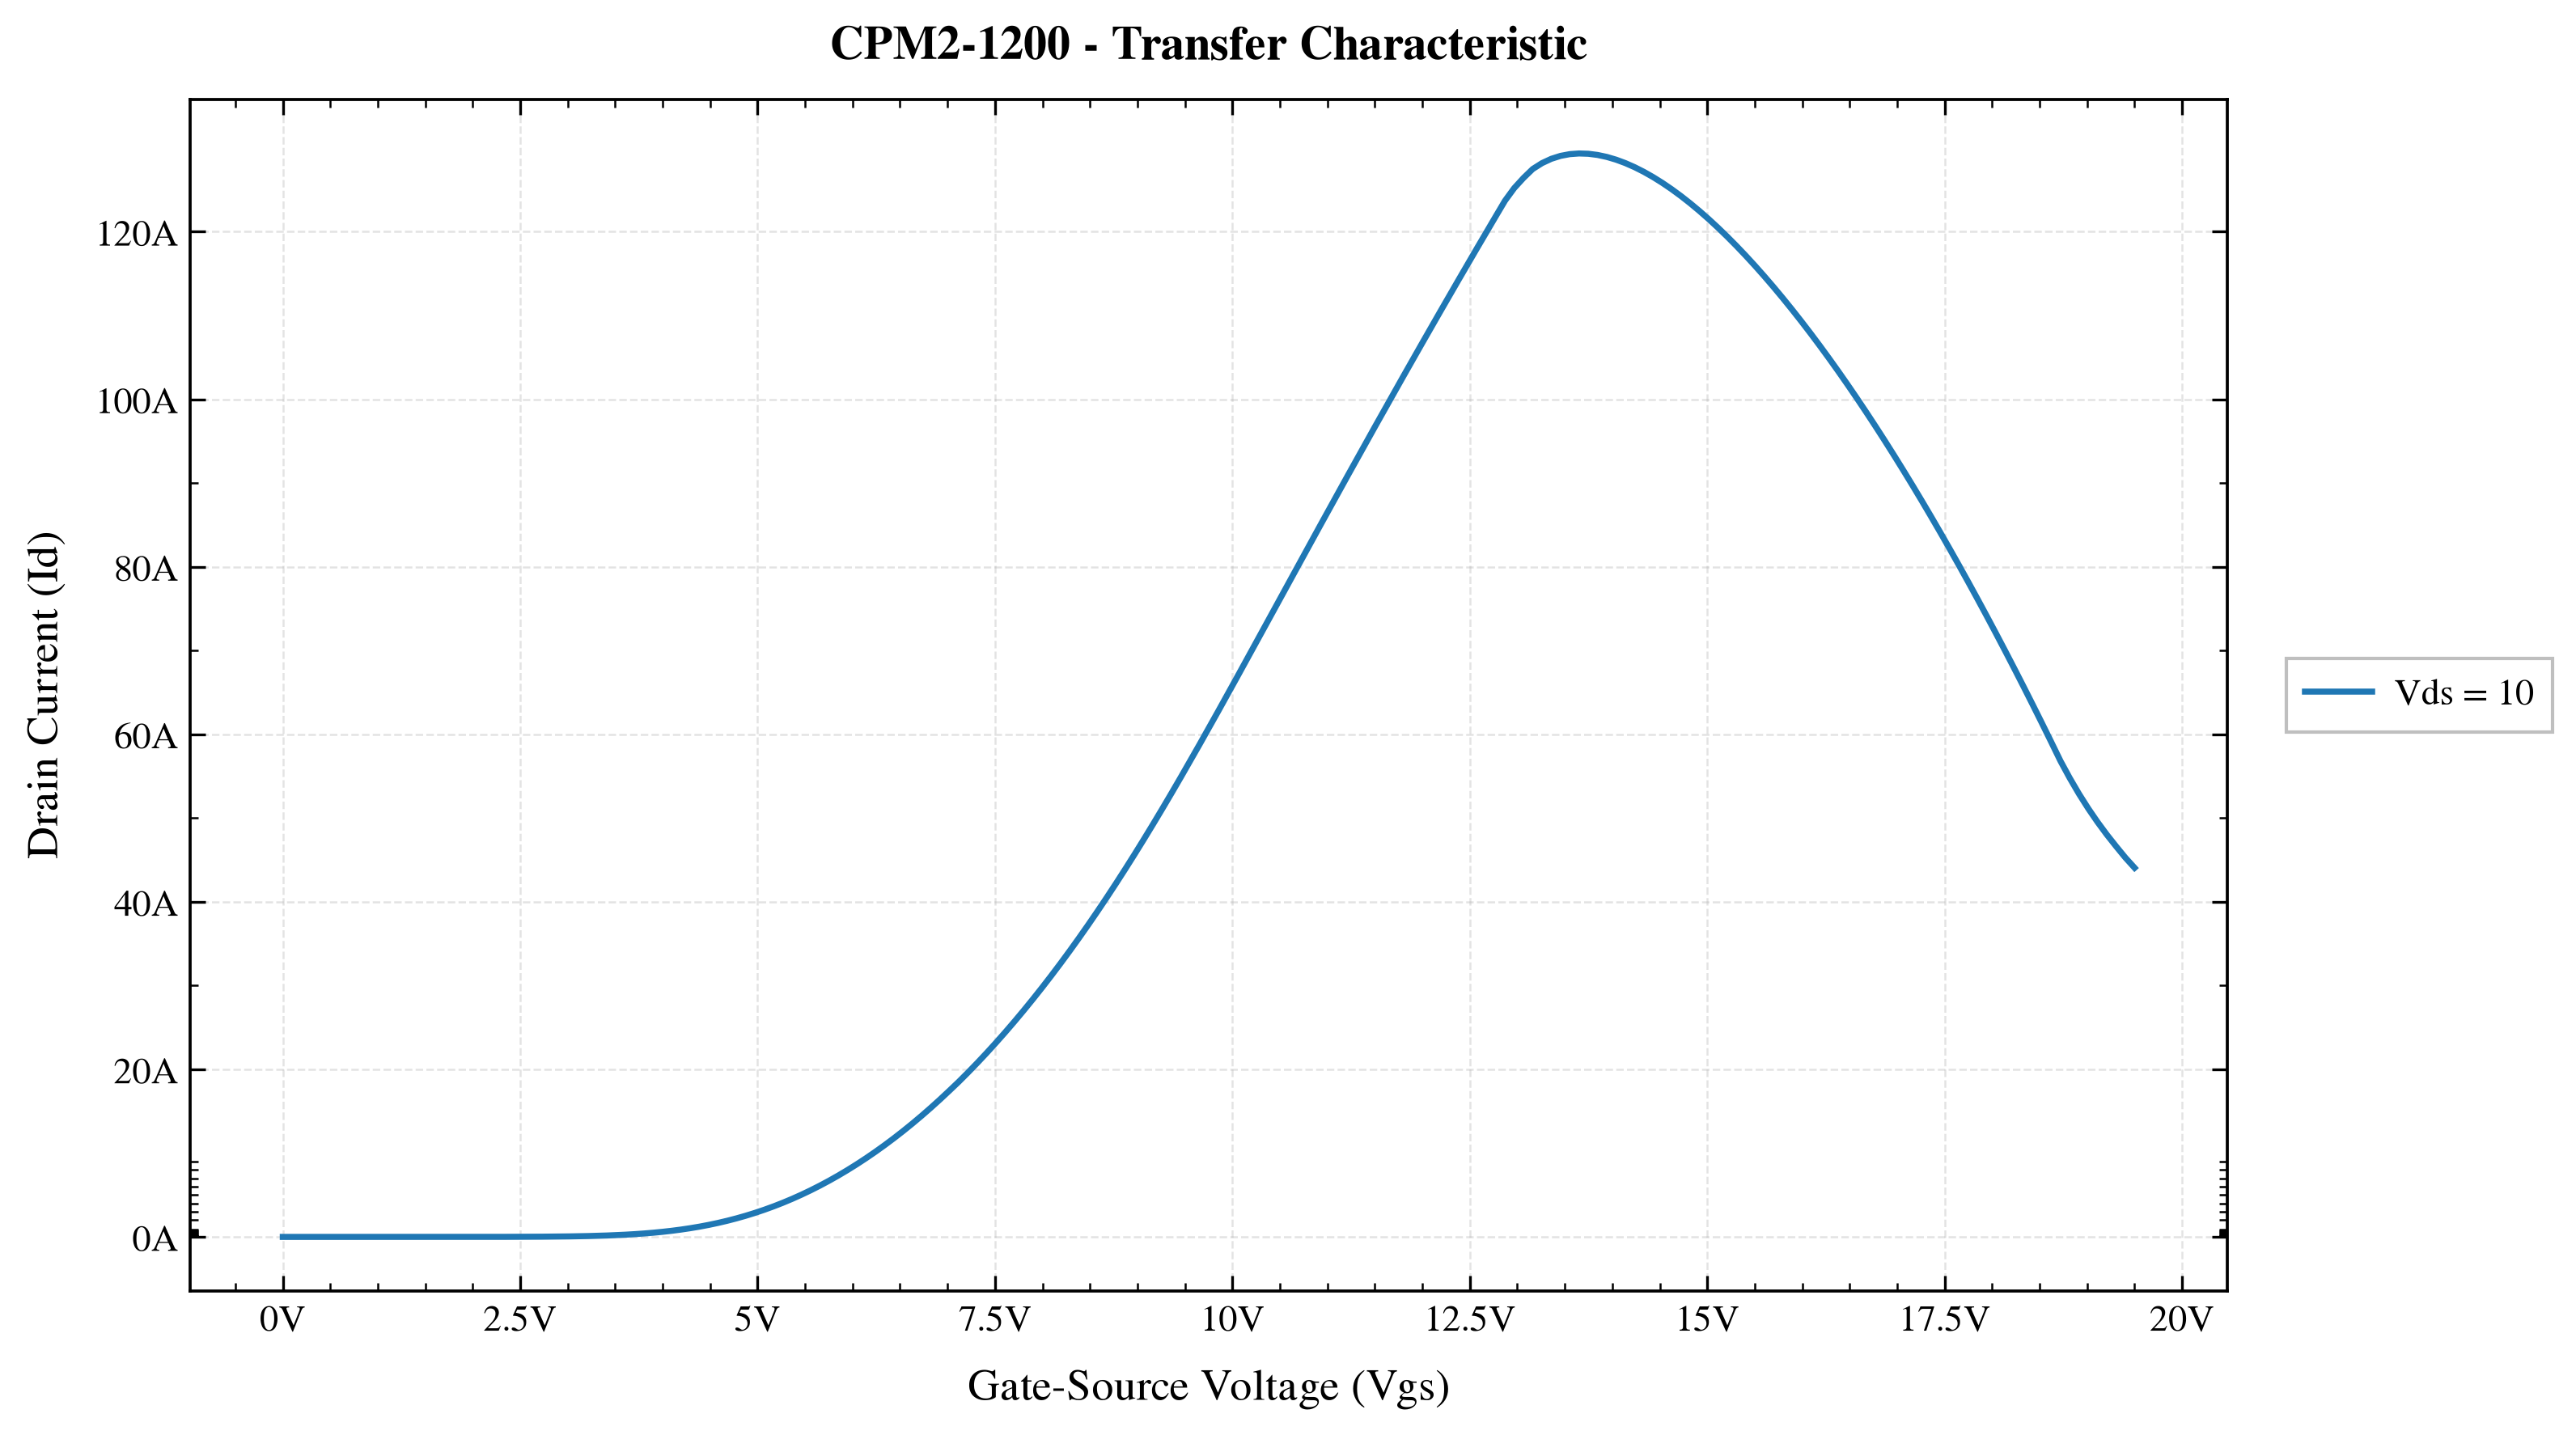

In [3]:
transfer_curve = static.run_transfer_characteristics(
    LIB, SUBCKT,
    vds_fixed=cond["Vds_fixed"], vgs_max=cond["Vgs_transfer_max"],
    vgs_points=cond["Vgs_transfer_points"], pin_roles=PIN_ROLES,
)
fig2, ax2 = plot_curves([transfer_curve], f"{TITLE} - Transfer Characteristic")
plt.show()

## Study 3 - On-State Resistance (Rds(on) vs Id)
Both gate drives from the config (primary + alternate datasheet condition).

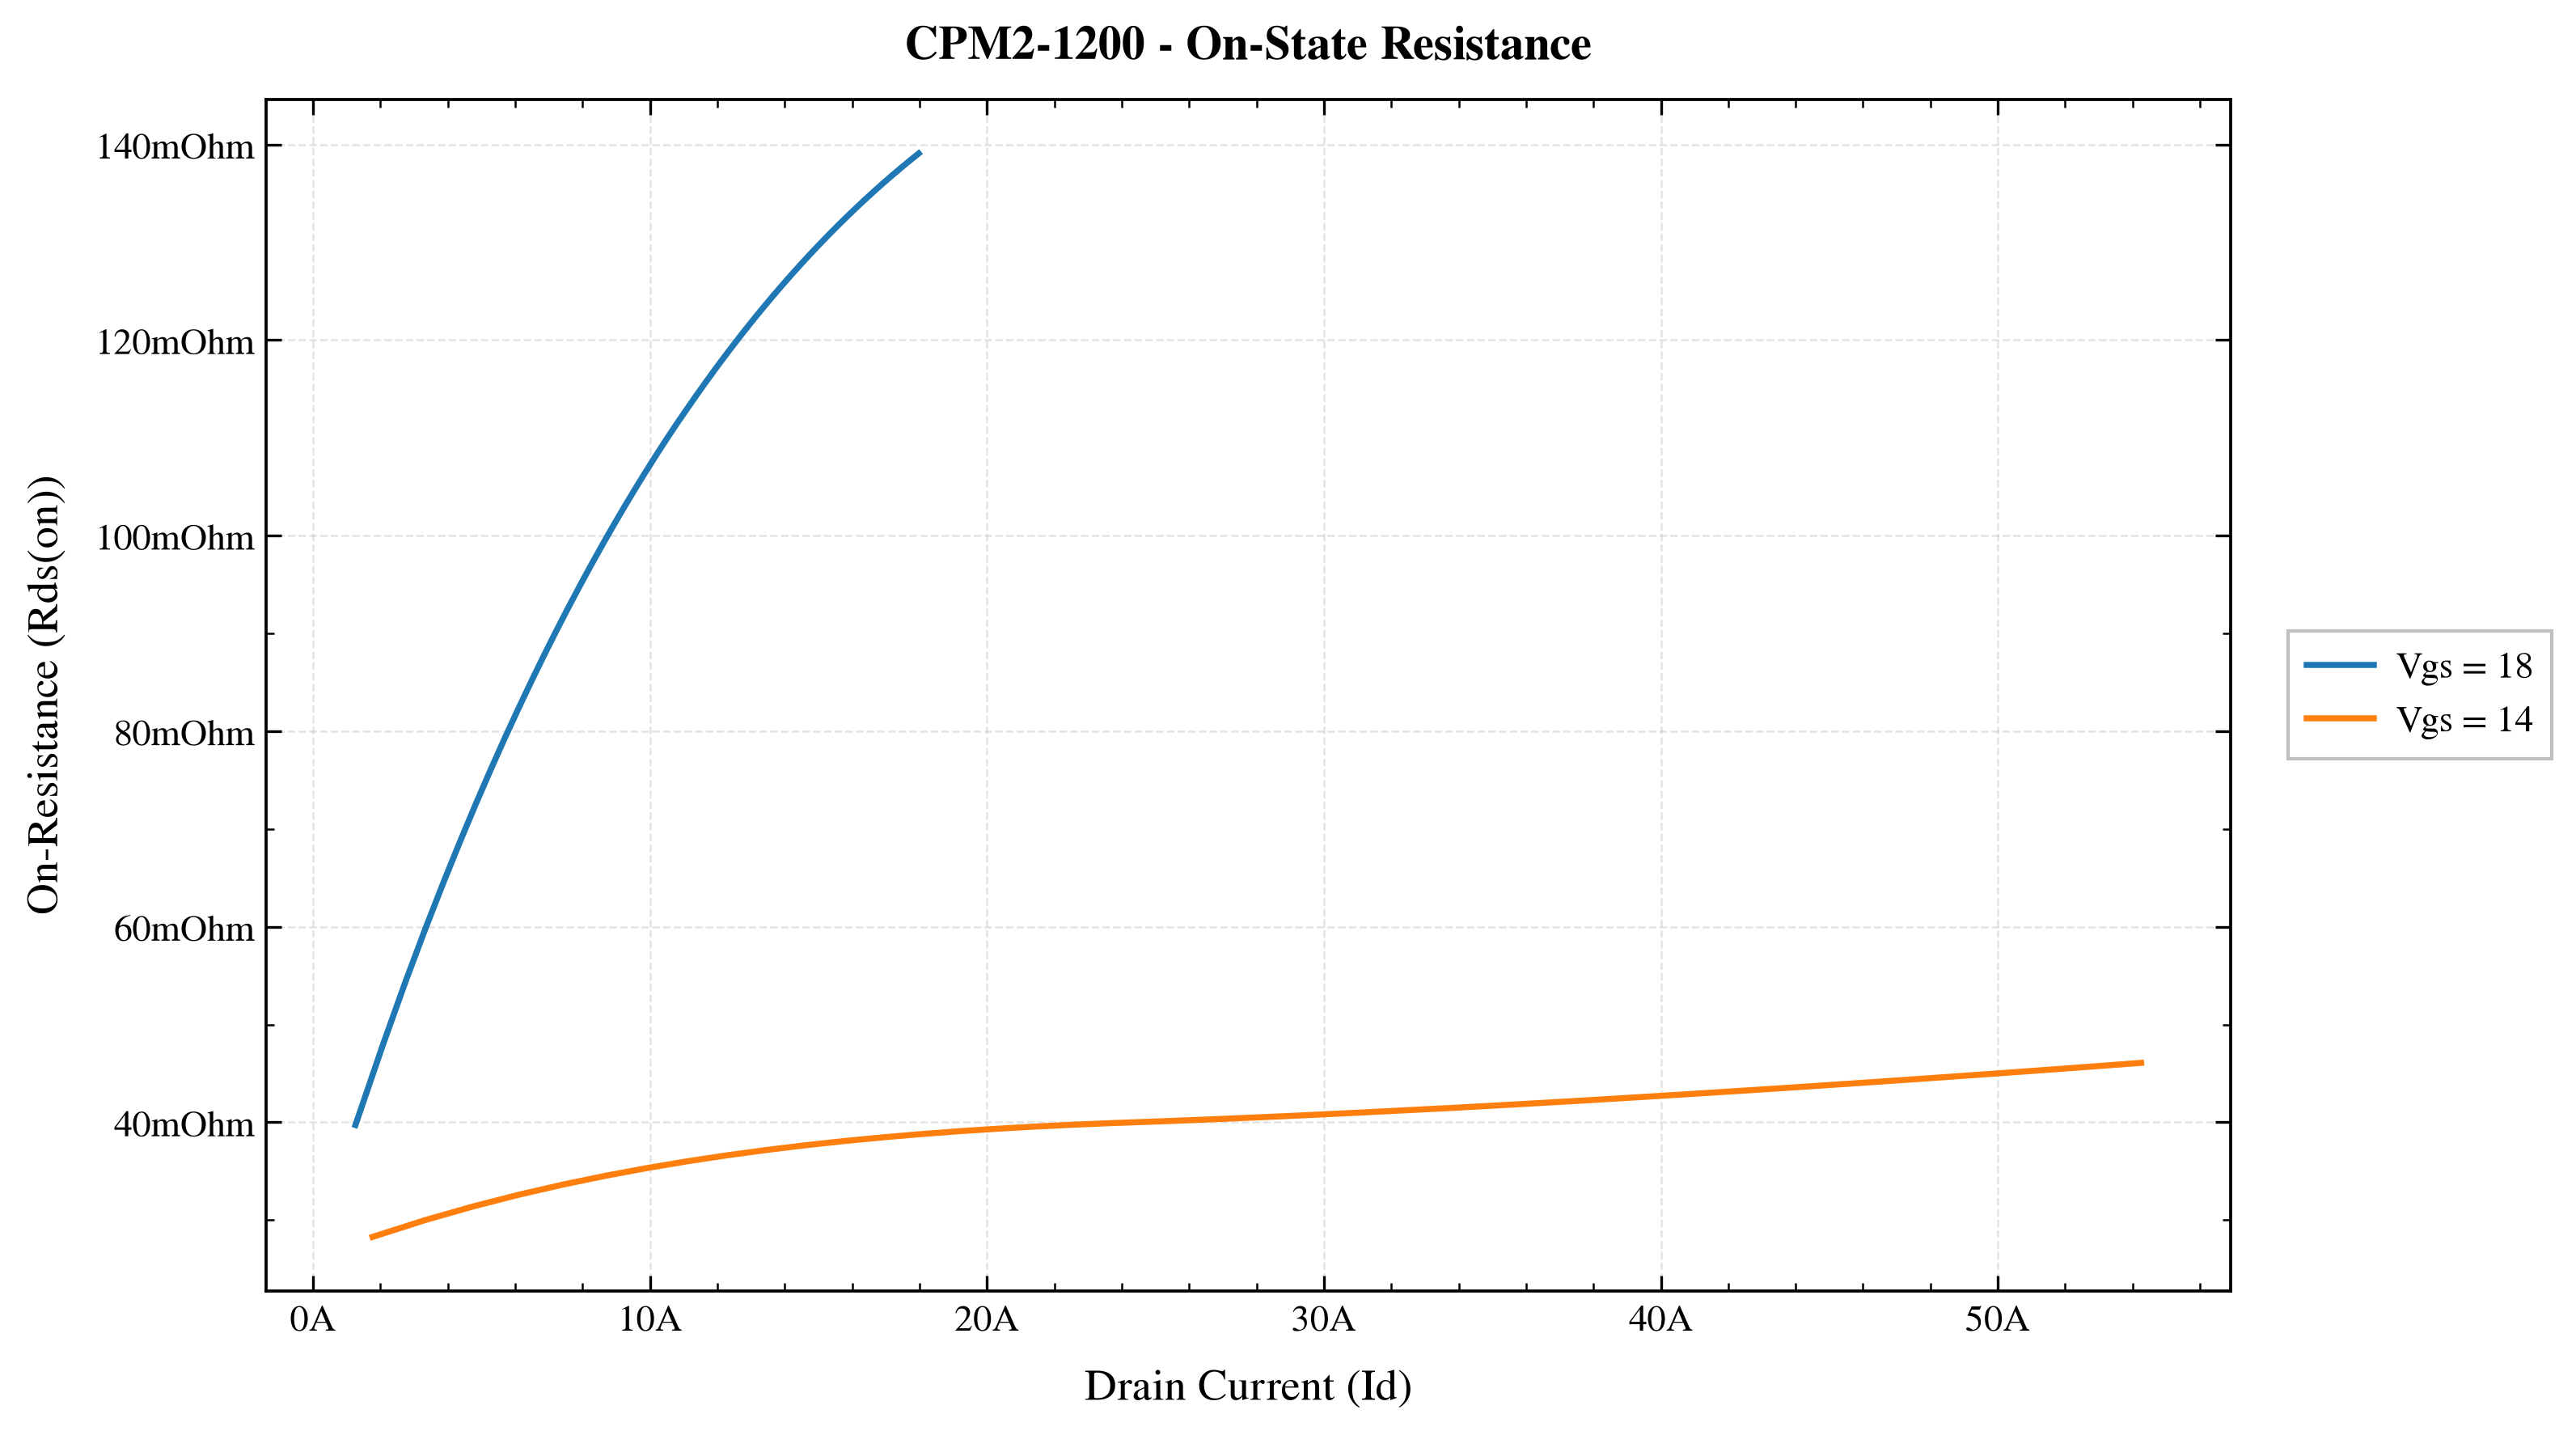

In [4]:
rds_curve = static.run_rds_on(
    LIB, SUBCKT, vgs=cond["Vgs_fixed"], vds_max=cond["Vds_rds_max"],
    vds_points=cond["Vds_rds_points"], min_current=cond["Id_rds_min"],
    pin_roles=PIN_ROLES,
)
rds45_curve = static.run_rds_on(
    LIB, SUBCKT, vgs=cond["Vgs_alt"], vds_max=cond["Vds_rds_max"],
    vds_points=cond["Vds_rds_points"], min_current=cond["Id_rds_min"],
    pin_roles=PIN_ROLES,
)
fig3, ax3 = plot_curves([rds_curve, rds45_curve], f"{TITLE} - On-State Resistance")
plt.show()

## Study 4 - Capacitances vs Vds
Small-signal AC method at the config measurement frequency; sweep ceiling is
vendor-aware via `Vds_cap_max` (model breakdown limits).

Node name 'None' is a Python keyword


Too few parameters for subcircuit type "cpm2-1200-0025b" (instance: xxm1)


Too few parameters for subcircuit type "cpm2-1200-0025b" (instance: xxm1)


Too few parameters for subcircuit type "cpm2-1200-0025b" (instance: xxm1)


Node name 'None' is a Python keyword


Too few parameters for subcircuit type "cpm2-1200-0025b" (instance: xxm1)


... (93 outputs left out)

Too few parameters for subcircuit type "cpm2-1200-0025b" (instance: xxm1)


Too few parameters for subcircuit type "cpm2-1200-0025b" (instance: xxm1)


Too few parameters for subcircuit type "cpm2-1200-0025b" (instance: xxm1)


[capacitance] WARNING: Coss @ Vds=29.79V = 1.592e+08 F is non-physical (limit 1 mF); masking this point as NaN.
[capacitance] WARNING: Crss @ Vds=29.79V = 1.592e+08 F is non-physical (limit 1 mF); masking this point as NaN.
[capacitance] WARNING: Coss @ Vds=38.59V = 1.592e+08 F is non-physical (limit 1 mF); masking this point as NaN.
[capacitance] WARNING: Crss @ Vds=38.59V = 1.592e+08 F is non-physical (limit 1 mF); masking this point as NaN.
[capacitance] WARNING: Coss @ Vds=50.00V = 1.592e+08 F is non-physical (limit 1 mF); masking this point as NaN.
[capacitance] WARNING: Crss @ Vds=50.00V = 1.592e+08 F is non-physical (limit 1 mF); masking this point as NaN.


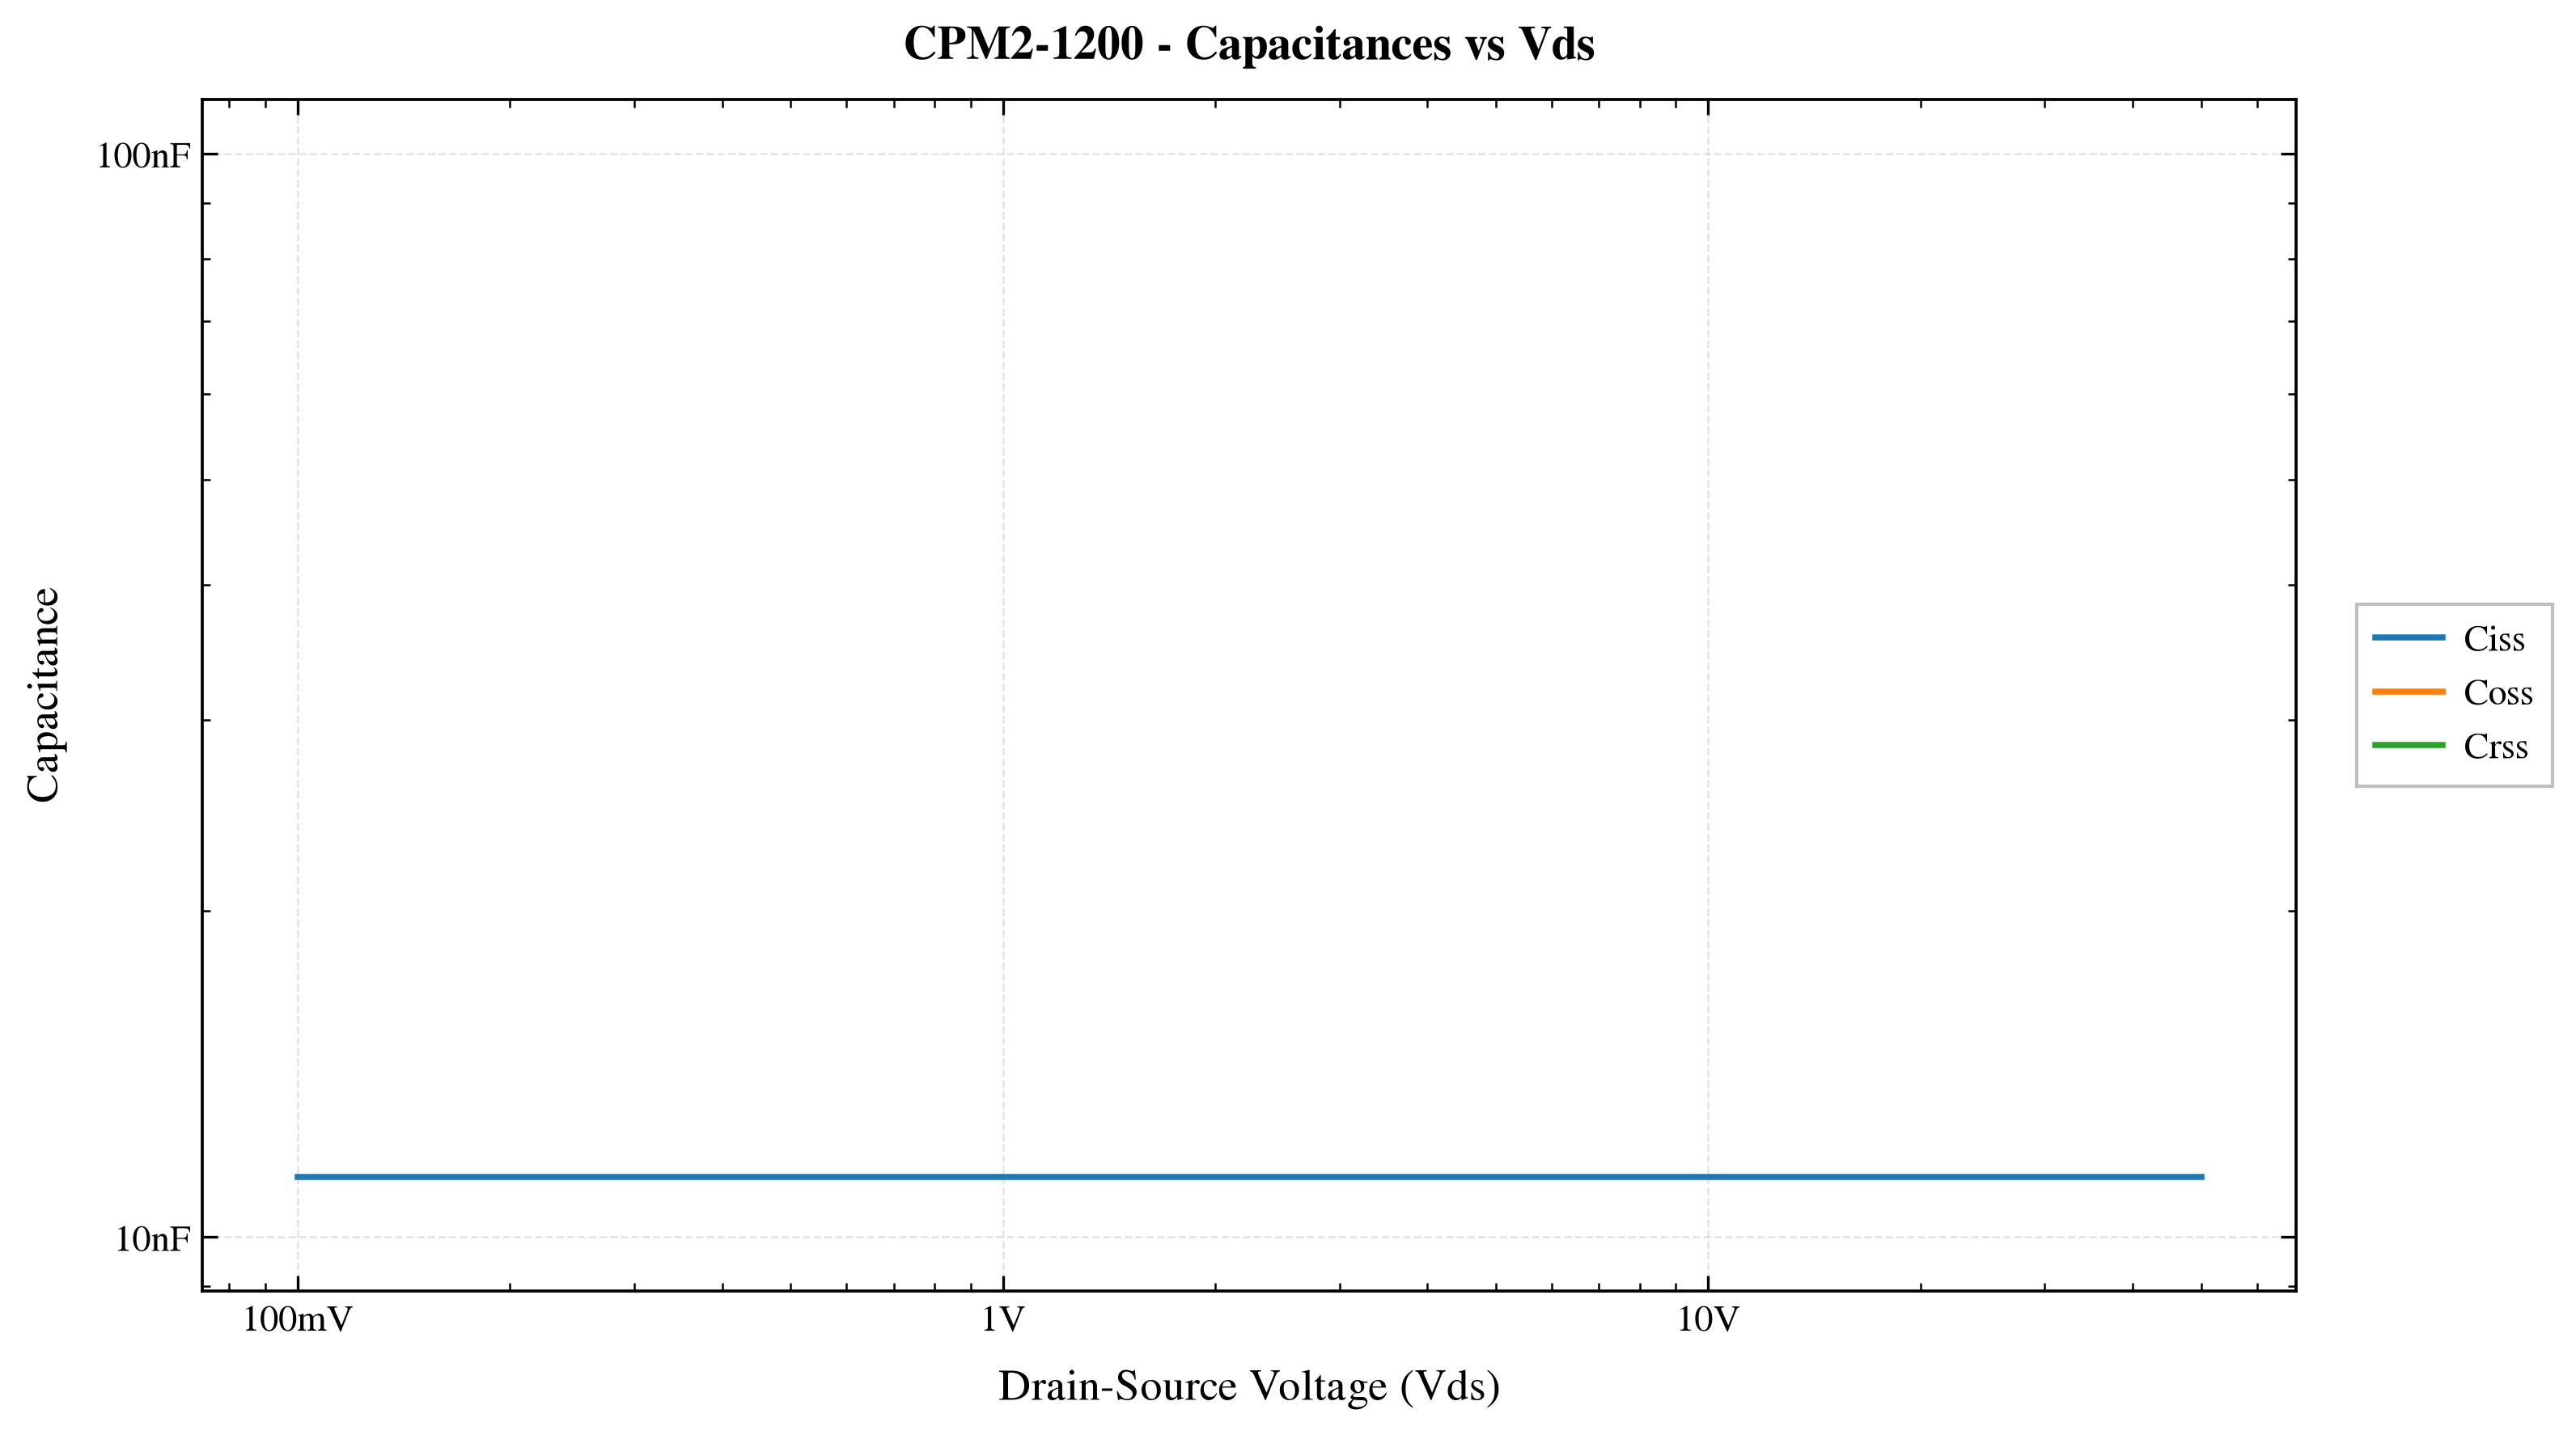

In [5]:
cap_curves = CapacitanceTestbench().run(
    LIB, SUBCKT, vds_min=cond["Vds_cap_min"],
    vds_max=cond["Vds_cap_max"], points=cond["Cap_points"],
    pin_roles=PIN_ROLES,
)
fig4, ax4 = plot_curves(
    cap_curves, f"{TITLE} - Capacitances vs Vds", x_log=True, y_log=True,
    y_label="Capacitance",
)
plt.show()

## Study 5 - Gate Charge Curve (quasi-static reconstruction)

Three-segment model built from Study 2 (transfer) and Study 4 (capacitance) data at
the configured datasheet conditions (`Id_load`, `Vbus`, `Vgs_qg_max`). When the config
supplies `Qgd_typ_nC`, the Miller segment is calibrated to it (VM-03).

Plateau voltage Vgp : 6.22 V
Qgs                 : 70.70 nC
Qgd (Miller)        : nan nC
Tail charge         : nan nC
Total Qg @ 18.0V     : nan nC


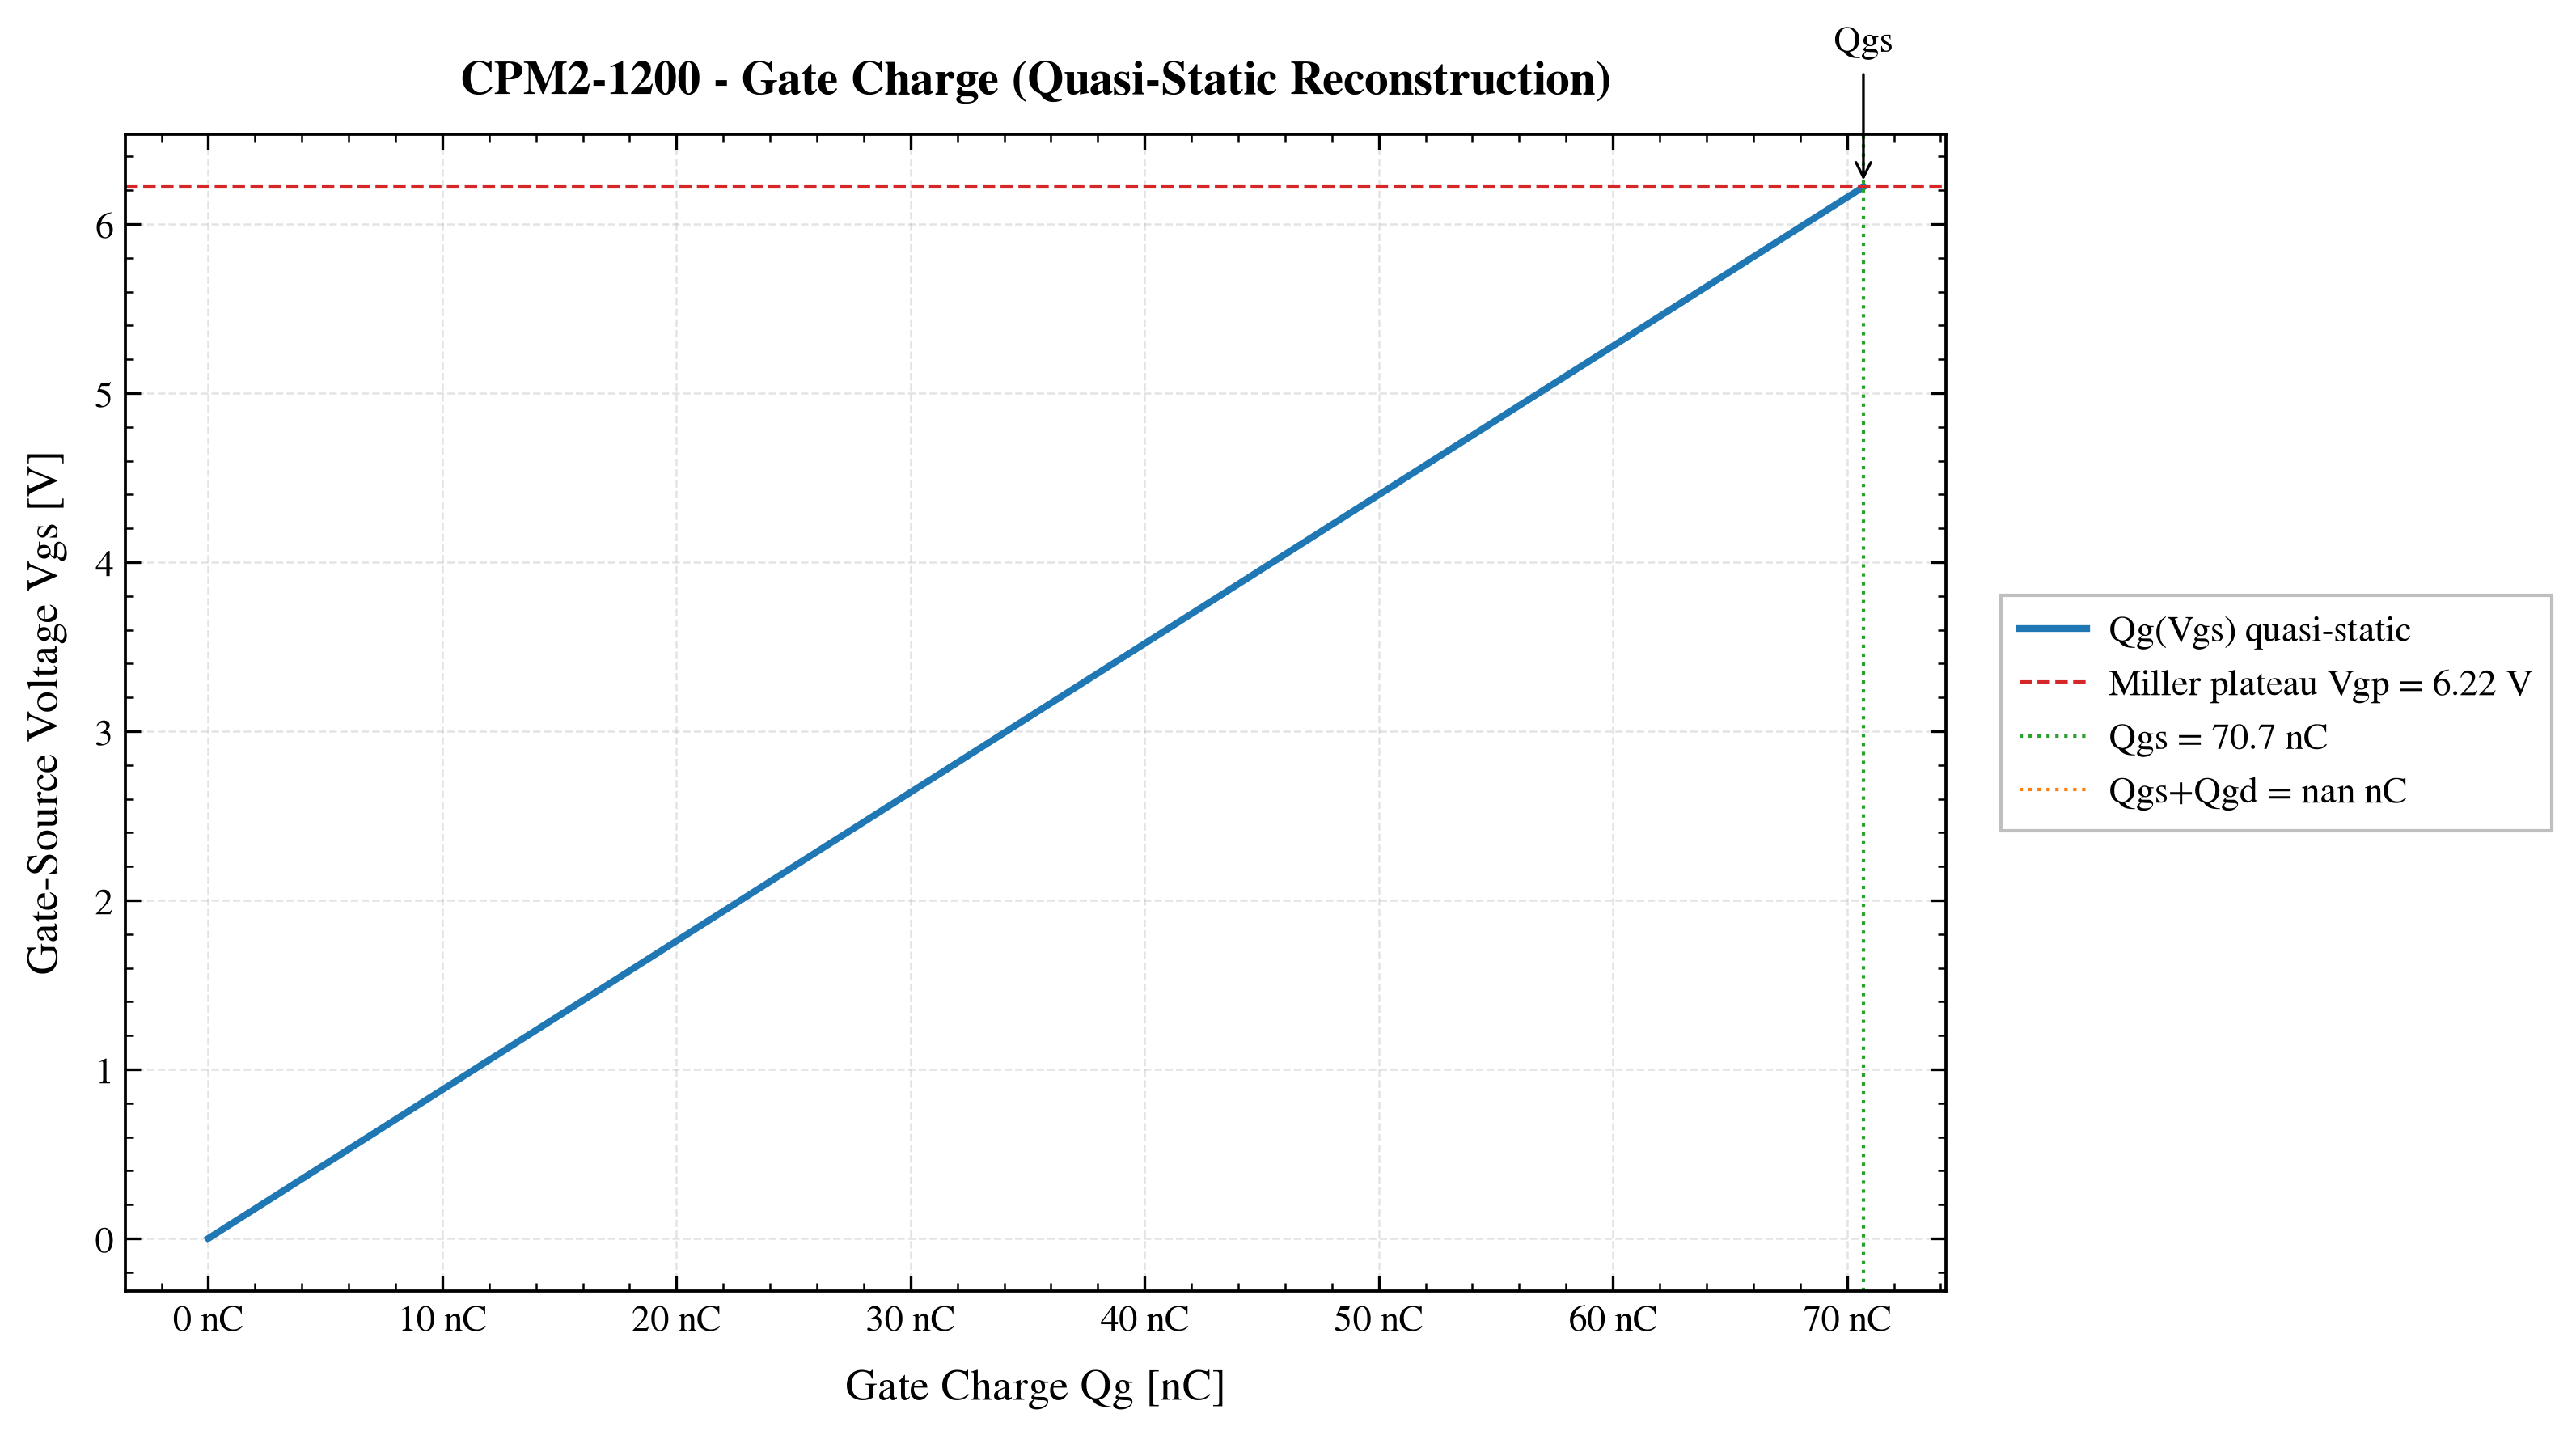

In [6]:
qgd_typ = cond.get("Qgd_typ_nC")   # VM-03 calibration (IR only; TI/EPC need none)
df_qg, bp = reconstruct_gate_charge(
    transfer_curve, cap_curves[0], cap_curves[2],
    v_bus=cond["Vbus"], i_load=cond["Id_load"], v_gs_max=cond["Vgs_qg_max"],
    v_ds_on=cond["Vds_on"], qgd_cal_nC=qgd_typ,
)
print(f"Plateau voltage Vgp : {bp['v_plateau_V']:.2f} V")
print(f"Qgs                 : {bp['q_gs_nC']:.2f} nC")
print(f"Qgd (Miller)        : {bp['q_gd_nC']:.2f} nC"
      + ("" if qgd_typ is None else f"   (calibrated to datasheet typ {qgd_typ})"))
print(f"Tail charge         : {bp['q_tail_nC']:.2f} nC")
print(f"Total Qg @ {cond['Vgs_qg_max']}V     : {bp['q_total_nC']:.2f} nC")

fig5, ax5 = plot_gate_charge(df_qg, bp, device_name=TITLE)
plt.show()

## Study 6 - Reverse Conduction (gate off)

Si MOSFETs: body-diode forward characteristic. GaN FETs (e.g. EPC2216, no body
diode): the same topology measures reverse channel conduction. Voltage-driven,
capped at the config's `Vsd_max`.

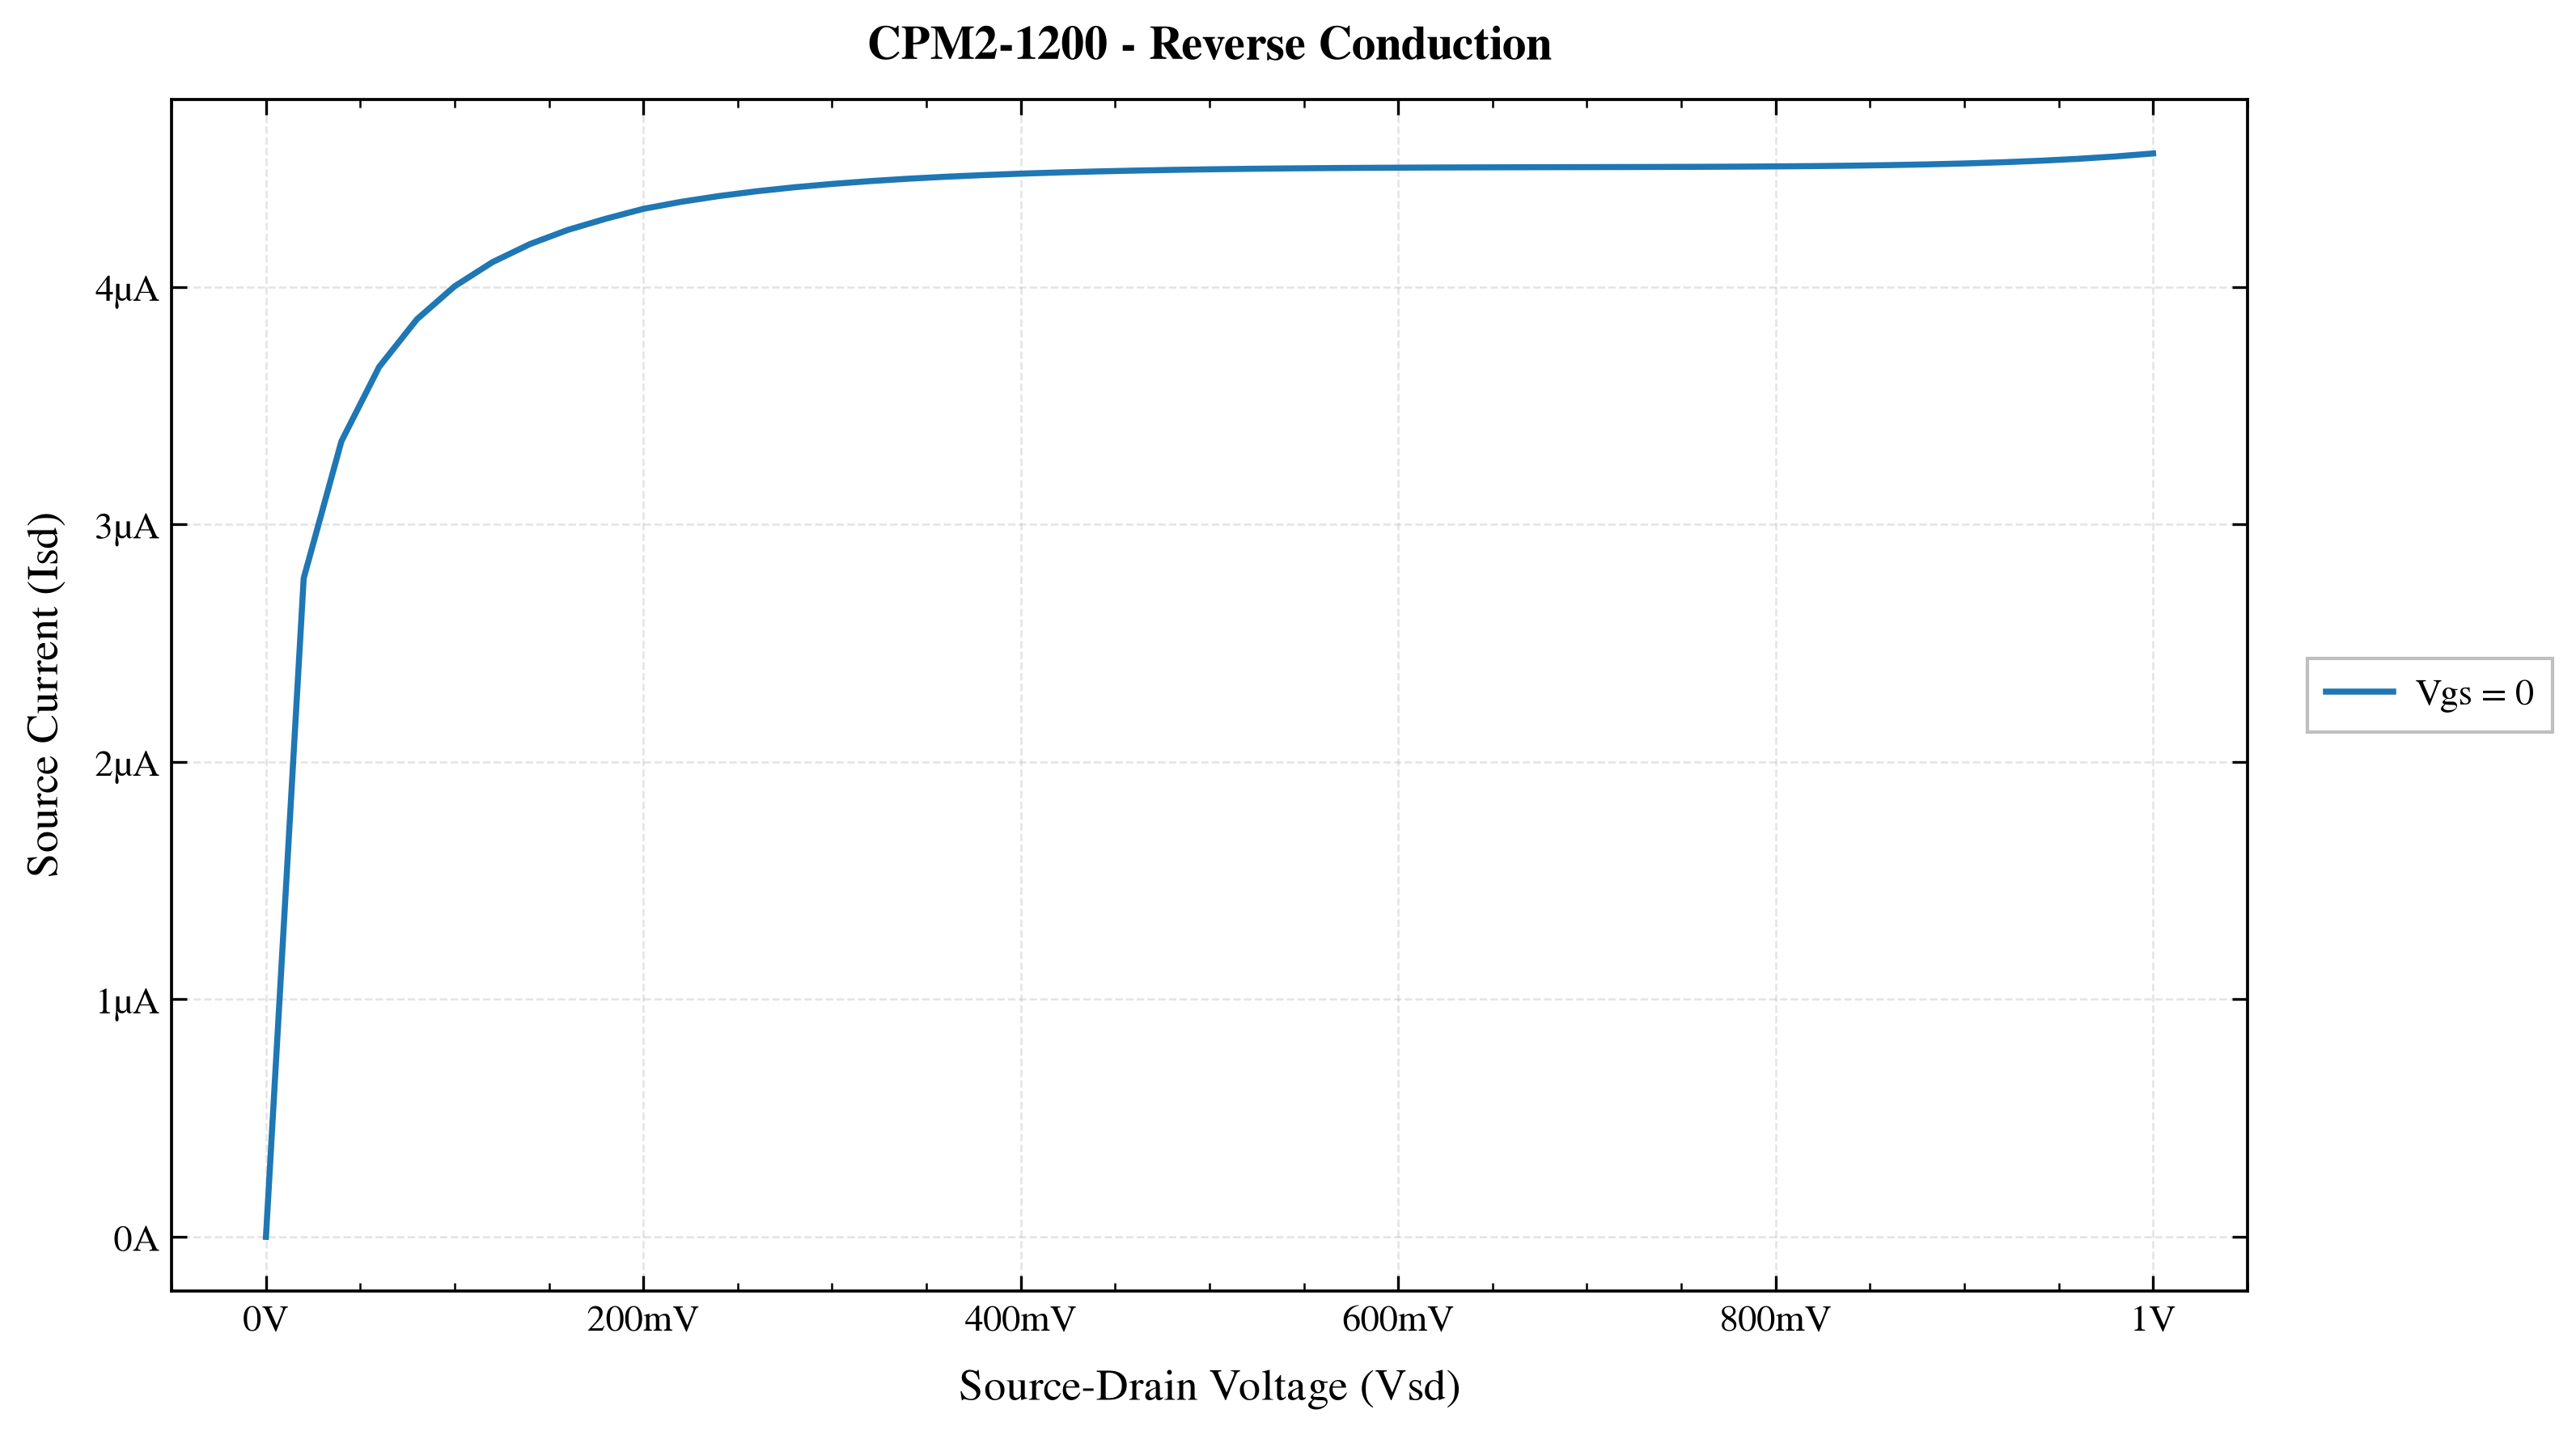

In [7]:
diode_curve = static.run_body_diode(LIB, SUBCKT, vsd_max=cond["Vsd_max"],
                                    points=cond["Vsd_points"],
                                    pin_roles=PIN_ROLES)
fig6, ax6 = plot_curves([diode_curve], f"{TITLE} - Reverse Conduction")
plt.show()

## Study 7 - Gate Threshold Voltage (constant-current method)

Datasheet convention: gate shorted to drain (`Vds = Vgs`), interpolate `Vgs` at the
configured `Id_th_target`. Note EPC2216's datasheet quotes Vth @ 11 mA (GaN), not
the Si-standard 250 uA — the config's `Id_th_target` reflects that.

> **Known model limitation:** behavioral/LEVEL=1 macromodels may have a hard
> threshold; the extracted value can sit outside the datasheet spec band.
> Vendor-model artifact, not an extraction error (see `vendor_model_defects.md`).

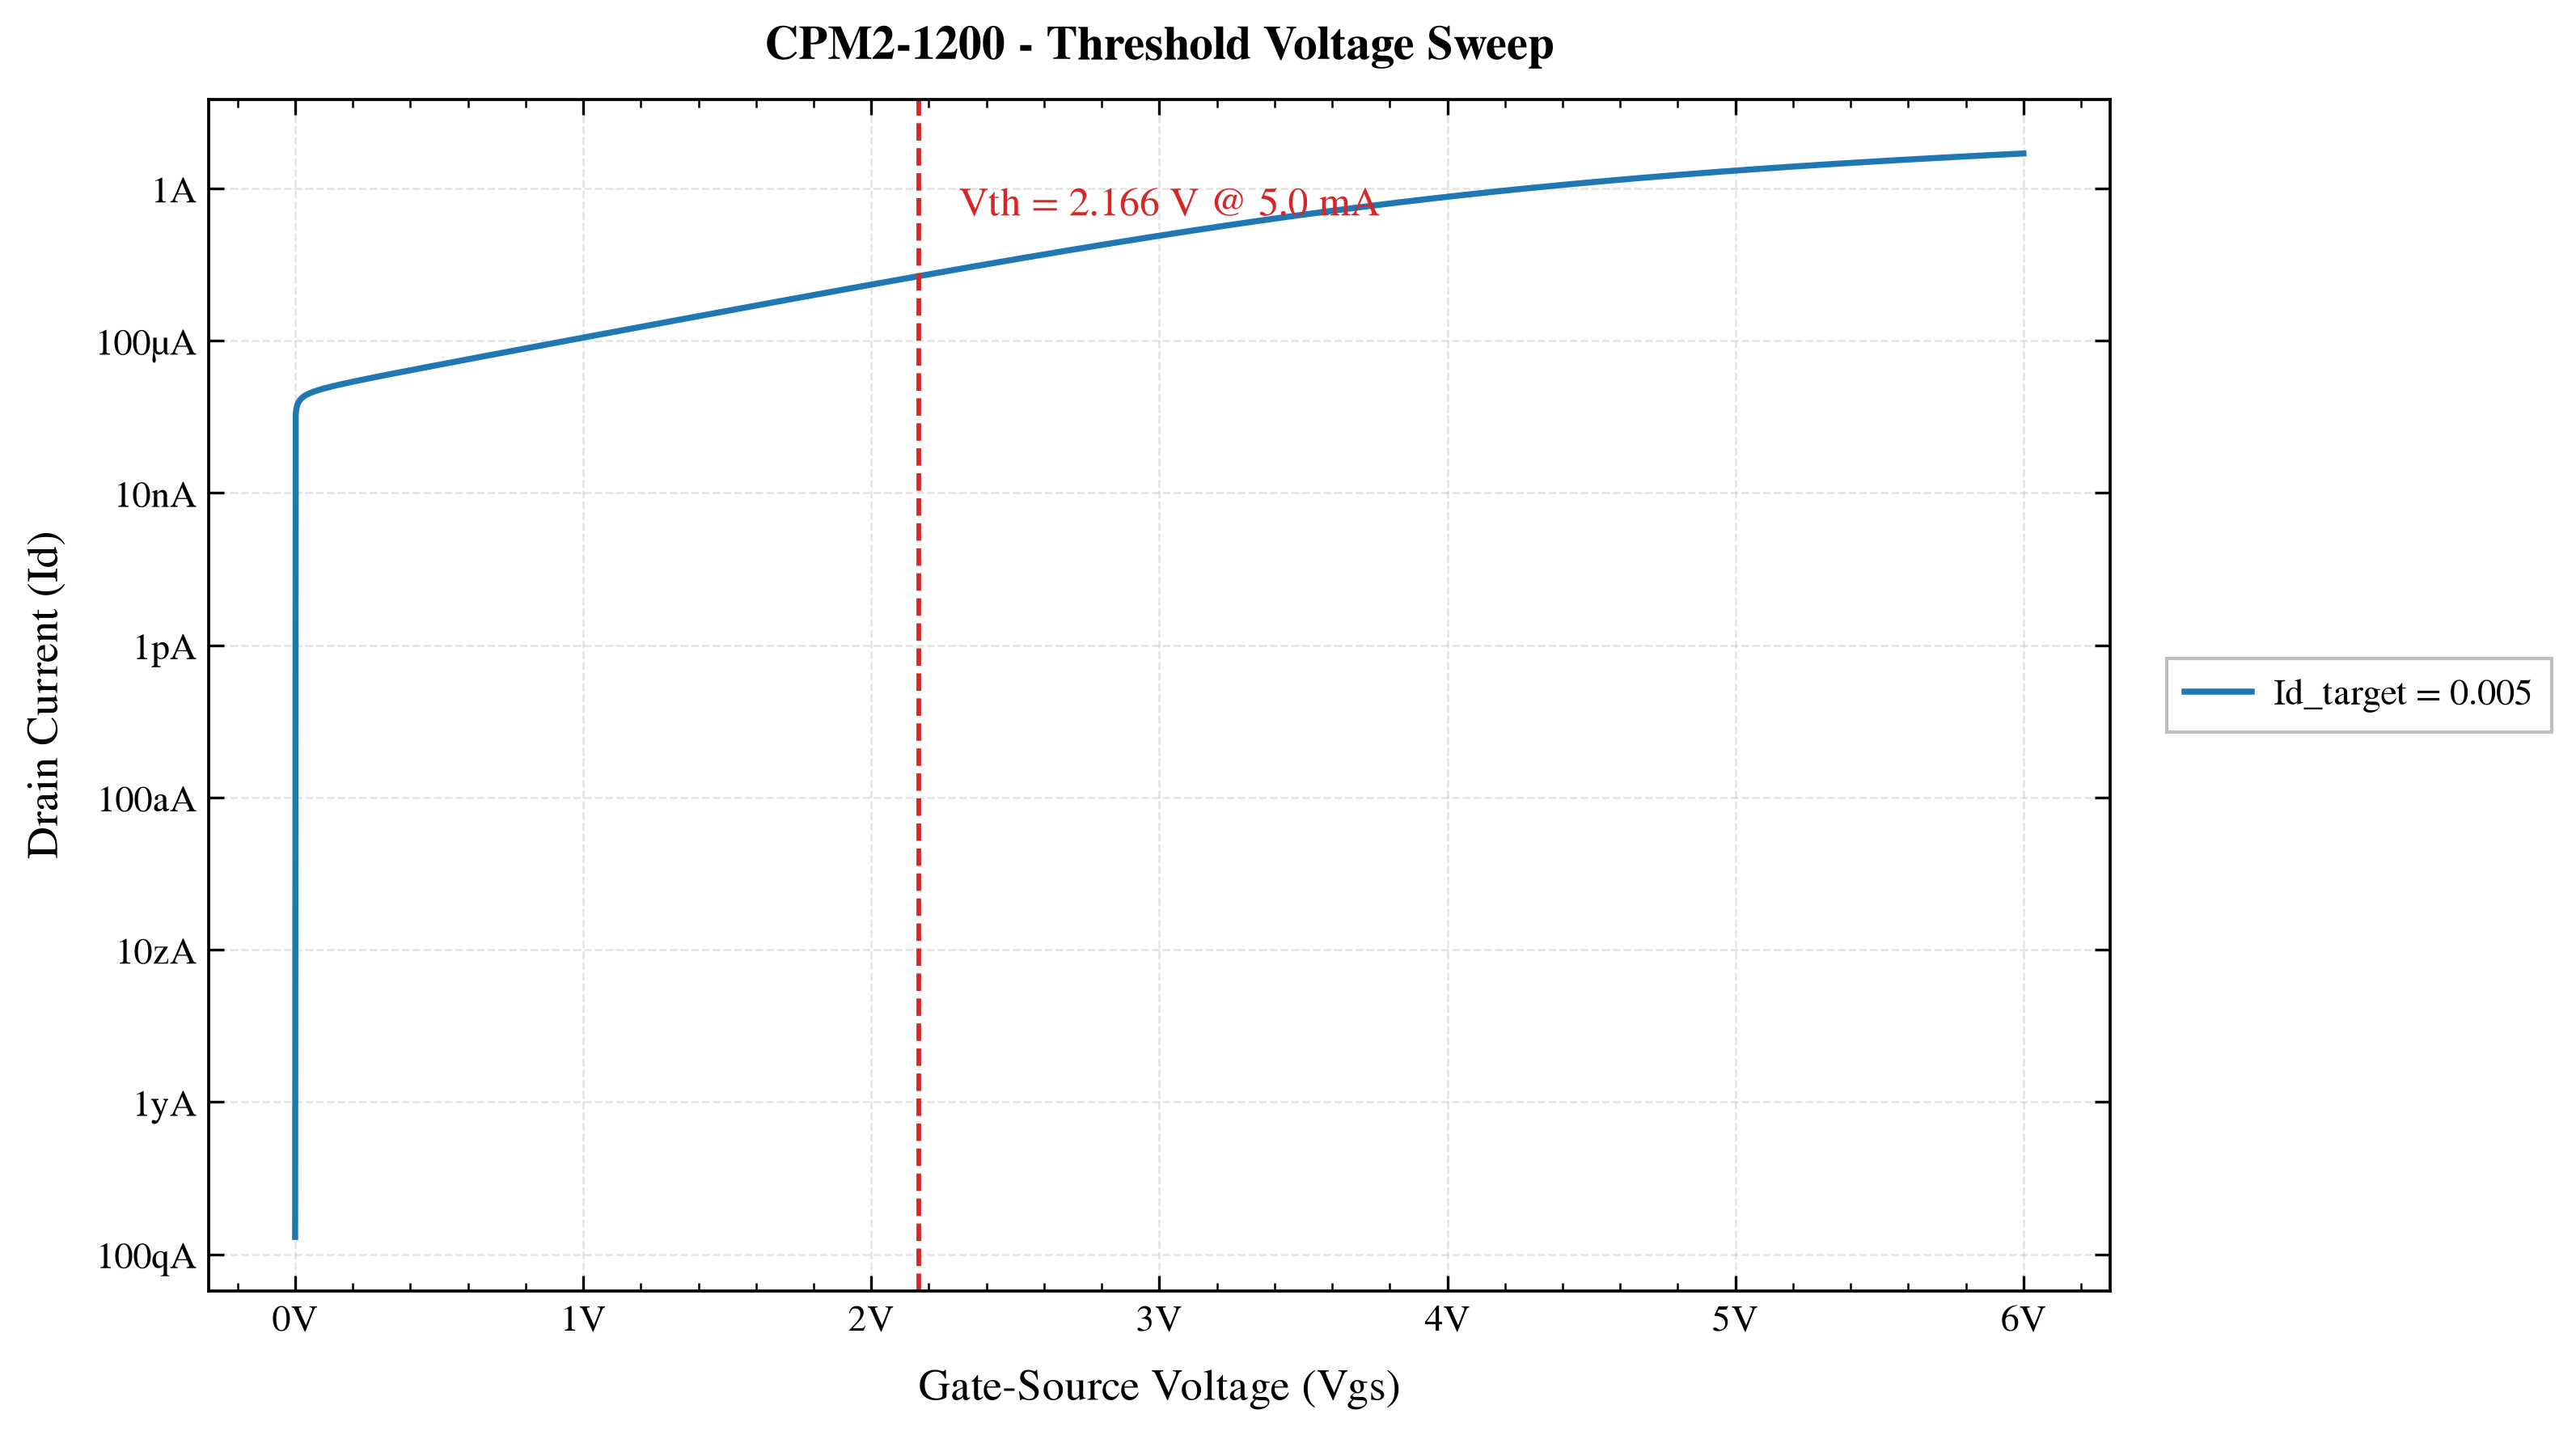

In [8]:
vth_curve, v_th = static.run_threshold_voltage(
    LIB, SUBCKT, i_target=cond["Id_th_target"], v_max=cond["Vgs_th_max"],
    pin_roles=PIN_ROLES,
)
fig7, ax7 = plot_curves([vth_curve], f"{TITLE} - Threshold Voltage Sweep", y_log=True)
ax7.axvline(v_th, color="tab:red", linestyle="--", linewidth=1.4)
ax7.annotate(
    f"Vth = {v_th:.3f} V @ {cond['Id_th_target'] * 1e3:.1f} mA",
    xy=(v_th, cond["Id_th_target"]), xytext=(12, 18), textcoords="offset points",
    fontsize=12, color="tab:red",
)
plt.show()

## Extracted Datasheet Figures
Interpolated at the config reference currents/voltages.

In [9]:
rx10, ry10 = rds_curve.to_numpy()
rx45, ry45 = rds45_curve.to_numpy()
id_ref = cond["Id_load"]
cap_ref_v = cond.get("Cap_ref_Vds", 7.5)

print(f"Rds(on) @ Vgs={cond['Vgs_fixed']}V, Id={id_ref:.0f}A : {np.interp(id_ref, rx10, ry10):.2f} mOhm")
print(f"Rds(on) @ Vgs={cond['Vgs_alt']}V, Id={id_ref:.0f}A : {np.interp(id_ref, rx45, ry45):.2f} mOhm")
print(f"Vgs(th) constant-current  : {v_th:.3f} V")
for c_ in cap_curves:
    print(f"{c_.name} @ Vds={cap_ref_v:.1f}V           : {np.interp(cap_ref_v, c_.x_data, c_.y_data) * 1e12:.0f} pF")
dx, dy = diode_curve.to_numpy()
print(f"Reverse Vsd @ Isd={id_ref:.0f}A      : {np.interp(id_ref, dy, dx) * 1e3:.1f} mV")
print(f"Gate charge Qg @ {cond['Vgs_qg_max']}V    : {bp['q_total_nC']:.2f} nC  (quasi-static reconstruction)")

Rds(on) @ Vgs=18.0V, Id=10A : 107.23 mOhm
Rds(on) @ Vgs=14.0V, Id=10A : 35.37 mOhm
Vgs(th) constant-current  : 2.166 V
Ciss @ Vds=7.5V           : 11368 pF
Coss @ Vds=7.5V           : nan pF
Crss @ Vds=7.5V           : nan pF
Reverse Vsd @ Isd=10A      : 1000.0 mV
Gate charge Qg @ 18.0V    : nan nC  (quasi-static reconstruction)
